# TREX quick start

This notebook runs TREX on a small synthetic target: describe the star and its neighbours,
give the phase-folded light curve, call `calc_probs`, and read `FPP` and `NFPP`. The star,
light curve and neighbours are invented; the probabilities do not describe a real star.
TREX does not validate or confirm planets.

TREX 1.0 is not on PyPI. Install it from the GitHub source with
`pip install "git+https://github.com/shenfurkan/TREX"`, or run `pip install .` in a clone; the
import is `import trex`.

The default budget is 1,000,000 draws per scenario. The executed cell below records
the actual draw budget, wall time and hardware. These probabilities describe only the
synthetic input, not an observed star. For a terminal version, see the README.


In [1]:
import hashlib
import os
from pathlib import Path

import numpy as np

from trex.scene import TargetScene
from trex.target import target

work = Path("trex-quickstart")
work.mkdir(exist_ok=True)

## 1. Background population

TREX draws unresolved background stars from a TRILEGAL simulation of the field
(Girardi et al. 2005, A&A 436, 895). Columns: TESS magnitude, log Teff, log g, mass (M☉) and
[M/H]. A real field has hundreds of rows; two are enough here. TRILEGAL output ends with a
`#TRILEGAL normally terminated` line, which TREX checks so that a truncated download is refused.

In [2]:
background = work / "trilegal.csv"
background.write_text(
    ",TESS,logTe,logg,Mact,[M/H]\n"
    "0,14.0,3.70,4.5,0.80,0.0\n"
    "1,16.0,3.60,4.7,0.50,0.0\n"
    "2,#TRILEGAL,normally,terminated,\n"
)

111

## 2. The scene

The scene is everything TREX needs to know about the sky around the target:

- the target star (mass, radius, Teff, TESS magnitude, parallax, metallicity with its source);
- the fraction of the target's light inside the photometric aperture, per sector;
- each resolved neighbour (Gaia source), its magnitude difference, separation and aperture fraction;
- a contrast curve from high-resolution imaging (separation in arcsec, Δmag);
- the background population and the sky area it was simulated for.

A neighbour without stellar parameters is kept, with the reason; TREX reports its scenarios as
unavailable instead of inventing a star.

In [3]:
target_fractions = [{"sector": 1, "fraction": 0.85}, {"sector": 2, "fraction": 0.80}]

scene = TargetScene(
    tic_id=100001, ra_deg=120.0, dec_deg=-30.0, sectors=[1, 2],
    M_s_Msun=1.02, R_s_Rsun=0.98, Teff_K=5778.0, Tmag=10.0, plx_mas=10.0,
    feh_dex=0.0,
    metallicity_provenance={"source": "caller-supplied", "quantity": "[Fe/H]",
                            "value_dex": 0.0, "uncertainty_dex": 0.1,
                            "citation": "Invented value for this synthetic example"},
    contrast_separations=[0.1, 1.0, 2.0], contrast_values=[1.0, 3.0, 5.0],
    target_aperture_flux_fractions=target_fractions,
    resolved_neighbors=[
        {"source_id": "100002", "M_s": 0.82, "R_s": 0.79, "delta_mag": 1.5,
         "separation_arcsec": 12.0,
         "aperture_flux_fractions": [{"sector": 1, "fraction": 0.1499}, {"sector": 2, "fraction": 0.1999}]},
        {"source_id": "100003", "M_s": None, "R_s": None, "delta_mag": 10.0,
         "separation_arcsec": 14.4,
         "aperture_flux_fractions": [{"sector": 1, "fraction": 0.0001}, {"sector": 2, "fraction": 0.0001}],
         "stellar_parameter_unavailable_reason": "no Gaia astrophysical parameters"},
    ],
    N_background=2, trilegal_cache=background,
    background_sha256=hashlib.sha256(background.read_bytes()).hexdigest(),
    background_area_sq_deg=0.1,
)

## 3. The light curve

Time is in days relative to the transit midpoint, flux is normalized, and `sigma` is the
per-point uncertainty. The dip and white noise are invented. The uncertainty is deliberately
large (0.5, or 50%) so the reduced 4,096-draw budget can integrate the scenario evidences;
with a realistic 1000 ppm uncertainty the same data need the production budget and this
reduced run would defer instead of reporting a probability. These are software-path numbers,
not a measurement of the synthetic star.

The model integrates every cadence over `exptime_days` (120 s here). These points are
individual 2-minute cadences, not phase-averaged bins, so the separate phase-bin width is
zero: `bin_integration_days=0.0` selects the native exposure box only. A nonzero width is
only for input already averaged into phase bins, and must be that bin's width.


In [4]:
rng = np.random.default_rng(1)
time = np.arange(-0.15, 0.15, 120.0 / 86400.0)        # 2-min cadence, days from mid-transit
sigma = np.full_like(time, 0.5)                        # deliberately large for a reduced-budget check
flux = np.where(np.abs(time) < 0.03, 0.992, 1.0) + rng.normal(0.0, 0.5, time.size)  # 8000 ppm dip
period_days = 3.2
exptime_days = 120.0 / 86400.0


## 4. Bind and run

`target.from_scene` attaches the scene to the target together with the sector weights, the
observed depth and the exposure. `input_artifacts` lists the input files with their contents'
SHA-256, so the result records exactly which files it was computed from.

In [5]:
star = target.from_scene(
    scene,
    sector_weights={1: 3.0, 2: 1.0}, depth_ppm=8000.0,
    exptime_days=exptime_days, bin_integration_days=0.0,
    random_seed=424242,
    input_artifacts={str(background): hashlib.sha256(background.read_bytes()).hexdigest()},
)

import platform, time as clock
N_DRAWS = int(os.environ.get("TREX_QUICKSTART_DRAWS", 1000000))
started = clock.perf_counter()
star.calc_probs(time, flux, sigma, period_days, exptime=exptime_days, N=N_DRAWS,
                escalation_checkpoint_directory=str(work / "checkpoint"))
import jax
devices = sorted({device.device_kind for device in jax.devices()})
print(f"wall time {clock.perf_counter() - started:.0f} s on {platform.machine()}, {os.cpu_count()} CPUs, JAX devices: {', '.join(devices)}")

print("draws per scenario:", N_DRAWS)
print("status:", star.trex_result.status)
print("FPP  =", star.FPP)
print("NFPP =", star.NFPP)


wall time 32857 s on x86_64, 4 CPUs, JAX devices: cpu
draws per scenario: 1000000
status: ok
FPP  = 0.8230314087781595
NFPP = 0.45729552288910985


## 5. Per-scenario results

One row per scenario and host: log evidence, effective sample size and normalized probability.
A scenario whose effective sample size is too small to trust is refined automatically; if it
still carries probability, TREX does not publish an FPP.

In [6]:
star.probs

,ID,scenario,M_s,R_s,P_orb,inc,b,ecc,w,R_p,M_EB,R_EB,prob
0,100001,TP,1.020000,0.980000,3.2,89.332722,0.175463,0.802145,255.863748,19.755326,0.000000,0.000000,0.141465
1,100001,EB,1.020000,0.980000,3.2,89.261991,0.162034,0.659127,303.417321,0.000000,0.215536,0.244070,0.170770
2,100001,EBx2P,1.020000,0.980000,6.4,73.211904,1.635441,0.887366,199.576316,0.000000,1.001454,1.081391,0.058327
3,100001,PTP,1.020000,0.980000,3.2,89.067739,0.240359,0.841339,284.546537,19.758909,0.000000,0.000000,0.035501
4,100001,PEB,1.020000,0.980000,3.2,73.329955,1.613048,0.832281,206.481767,0.000000,0.859186,0.887562,0.047185
5,100001,PEBx2P,1.020000,0.980000,6.4,75.223259,1.428902,0.885070,198.389782,0.000000,0.976372,1.044694,0.017726
6,100001,STP,0.976824,1.045355,3.2,89.508703,0.122917,0.671772,276.093914,19.744511,0.000000,0.000000,0.021714
7,100001,SEB,0.692201,0.722407,3.2,89.772439,0.094053,0.803846,268.079587,0.000000,0.433243,0.432232,0.034995
8,100001,SEBx2P,0.714904,0.746197,6.4,88.518535,0.956903,0.702311,271.571028,0.000000,0.687806,0.717580,0.015007
9,100001,DTP,1.020000,0.980000,3.2,89.452417,0.152925,0.730419,263.950219,19.989624,0.000000,0.000000,0.000003


## 6. Representative fits

The light curve with a representative draw of each scenario.

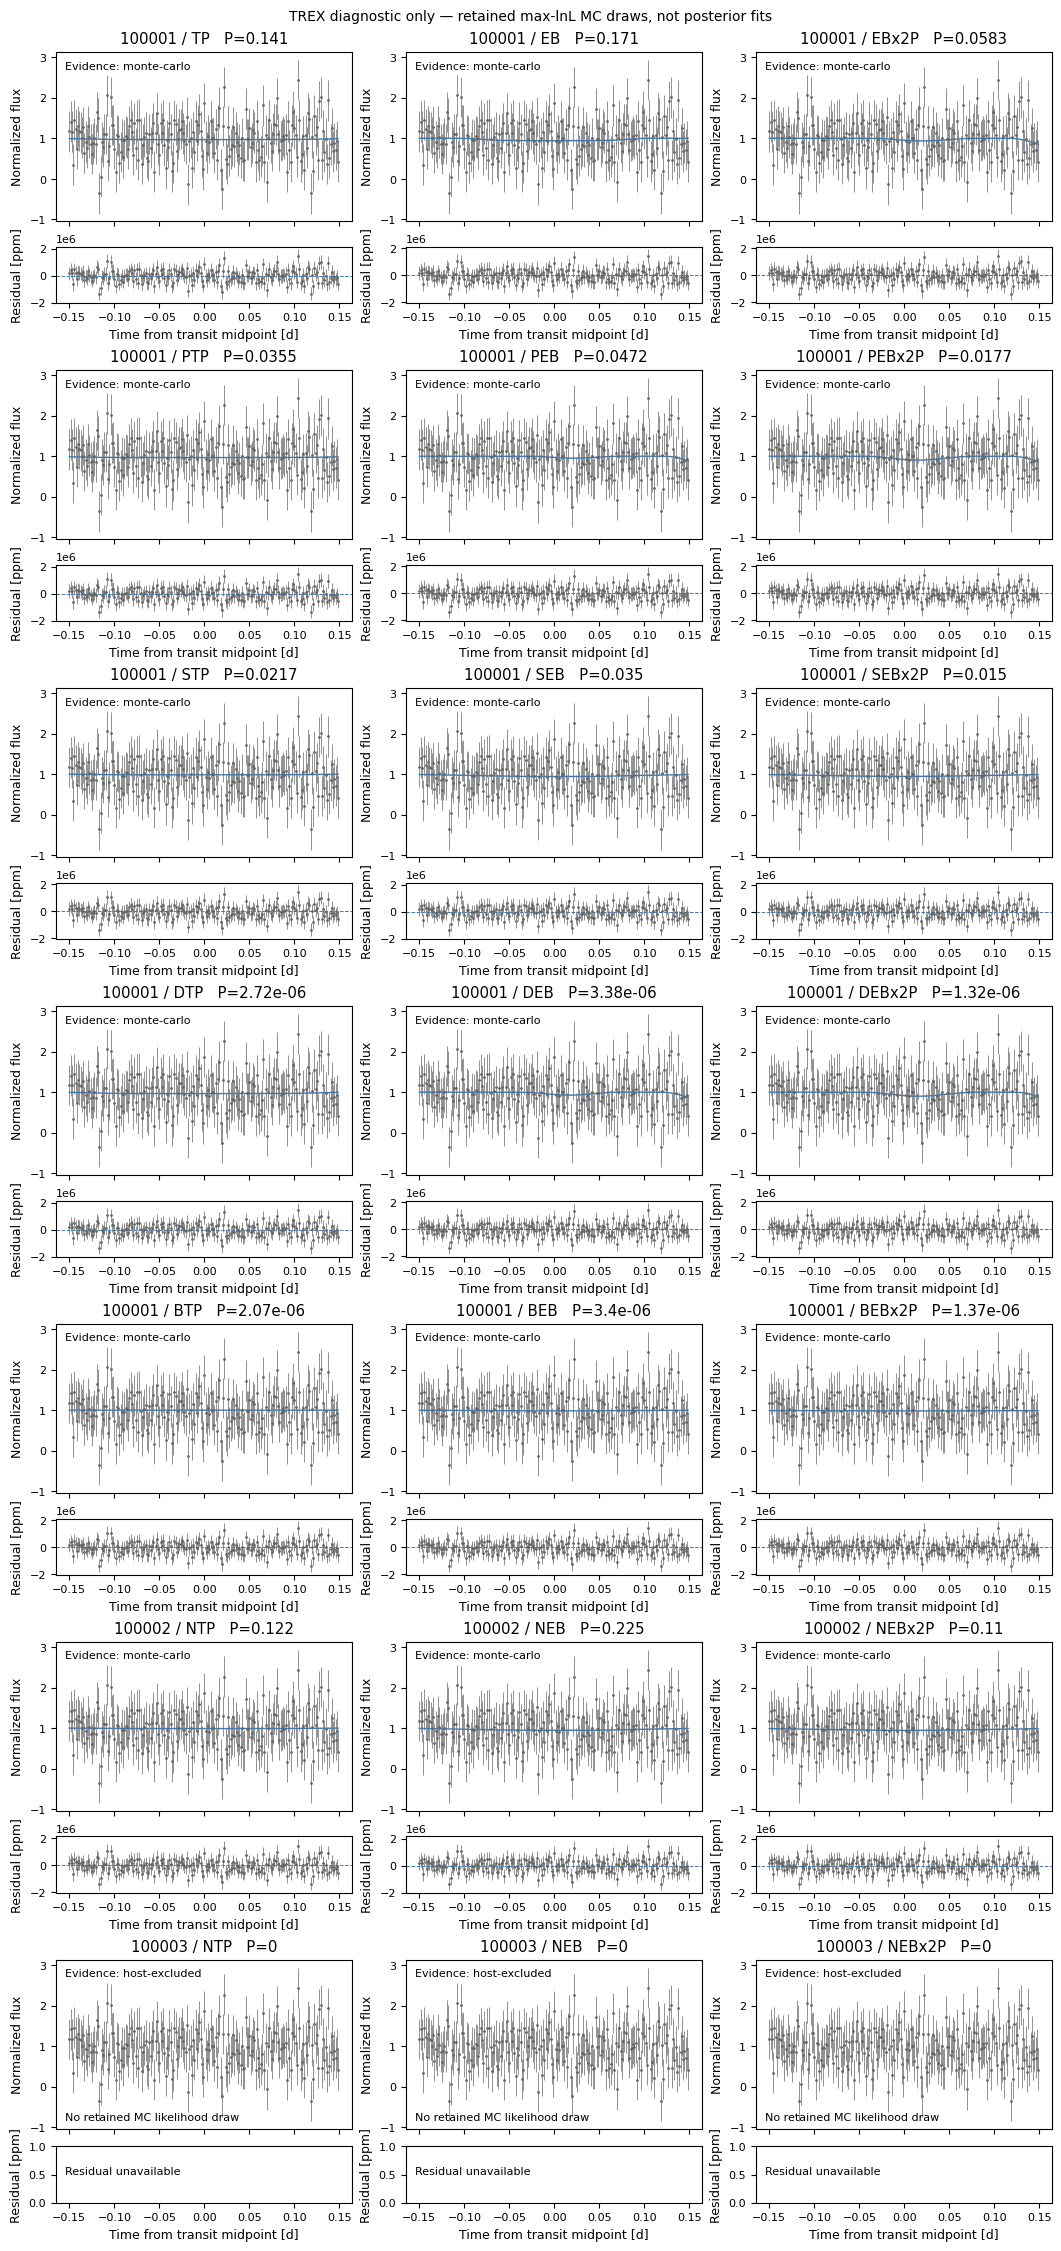

In [7]:
fig = star.plot_fits(time, flux, sigma)

## Saving and running a real target

`star.write_outputs("result")` writes `summary.json` and `scenarios.csv`.

Production uses 1,000,000 draws per scenario, the default here. Any explicit
`TREX_QUICKSTART_DRAWS` override is printed above; a reduced-budget execution is
a software-path check, not production-budget evidence.

For a real target, prepare an input directory (`trex-input.json`, `arrays.npz`,
`background.csv`; see the README) and run it from a terminal, where an interrupted run can
resume:

```bash
python -m trex.run INPUT_DIRECTORY OUTPUT_DIRECTORY
```
